# Indexing and ranking on FiQA
FiQA (from BEIR) has financial questions as queries and forum answers as passages. The queries come in train, dev and test splits. Parameters are tuned on dev and the final numbers are measured on test.

In [6]:
import itertools
import os
import time

import matplotlib.pyplot as plt
import pandas as pd
import pyterrier as pt
import seaborn as sns
from pyterrier.measures import nDCG

from helpers import (INDEX_CONFIGURATIONS, INDEX_FOLDER, RANKING_METRICS, build_retriever, controls_for_model,
                     index_path, load_documents, load_queries_and_qrels, milliseconds_per_query, open_index,
                     save_best_parameters, save_results)

if not pt.java.started():
    pt.java.init()

## Data

In [7]:
documents = load_documents()
train_queries, train_qrels = load_queries_and_qrels("train")
dev_queries, dev_qrels = load_queries_and_qrels("dev")
test_queries, test_qrels = load_queries_and_qrels("test")

pd.DataFrame({
    "documents": [len(documents)],
    "train queries": [len(train_queries)],
    "dev queries": [len(dev_queries)],
    "test queries": [len(test_queries)],
})

[INFO] Opening /Users/carlson/.ir_datasets/beir/fiqa/docs.pklz4/bin with direct file access


,documents,train queries,dev queries,test queries
0,57638,5500,500,648


In [8]:
documents["word_count"] = documents["text"].str.split().str.len()

all_queries = pd.concat([train_queries, dev_queries, test_queries])
all_queries["word_count"] = all_queries["query"].str.split().str.len()

pd.DataFrame({
    "document words": documents["word_count"].describe(),
    "query words": all_queries["word_count"].describe(),
}).round(1)

,document words,query words
count,57638.0,6648.0
mean,132.9,11.1
std,128.7,4.5
min,0.0,2.0
25%,57.0,8.0
50%,90.0,11.0
75%,159.0,14.0
max,2973.0,32.0


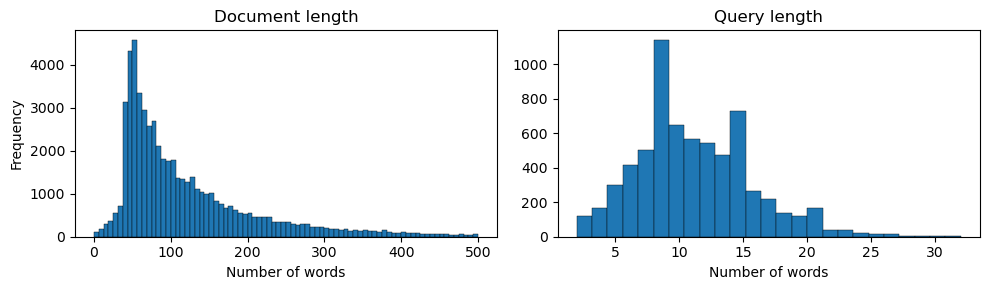

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].hist(documents["word_count"], bins=80, range=(0, 500), edgecolor="black", linewidth=0.3)
axes[0].set_title("Document length")
axes[0].set_xlabel("Number of words")
axes[0].set_ylabel("Frequency")

axes[1].hist(all_queries["word_count"], bins=25, edgecolor="black", linewidth=0.3)
axes[1].set_title("Query length")
axes[1].set_xlabel("Number of words")

plt.tight_layout()
plt.show()

## Indexes
Four indexes: without preprocessing, with stopword removal, with stemming and with both.

In [10]:
documents_as_records = documents[["docno", "text"]].to_dict(orient="records")
index_build_seconds = {}

for index_name, configuration in INDEX_CONFIGURATIONS.items():
    start_time = time.time()
    indexer = pt.IterDictIndexer(index_path(index_name), overwrite=True, **configuration)
    indexer.index(documents_as_records)
    index_build_seconds[index_name] = time.time() - start_time

21:19:20.541 [ForkJoinPool-2-worker-3] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (7915) - further warnings are suppressed
21:19:27.035 [ForkJoinPool-2-worker-3] WARN org.terrier.structures.indexing.Indexer -- Indexed 38 empty documents
21:19:27.270 [ForkJoinPool-3-worker-3] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (7915) - further warnings are suppressed
21:19:32.459 [ForkJoinPool-3-worker-3] WARN org.terrier.structures.indexing.Indexer -- Indexed 39 empty documents
21:19:32.581 [ForkJoinPool-4-worker-3] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (7915) - further warnings are suppressed
21:19:38.027 [ForkJoinPool-4-worker-3] WARN org.terrier.structures.indexing.Indexer -- Indexed 38 empty documents
21:19:38.129 [ForkJoinPool-5-worker-3] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (7915) - further warnings are suppr

In [11]:
def folder_size_in_megabytes(folder_path: str) -> float:
    total_bytes = 0
    for current_folder, _, file_names in os.walk(folder_path):
        for file_name in file_names:
            total_bytes += os.path.getsize(os.path.join(current_folder, file_name))
    return total_bytes / 1e6


indexes = {index_name: open_index(index_name) for index_name in INDEX_CONFIGURATIONS}

index_rows = {}
for index_name, index in indexes.items():
    statistics = index.getCollectionStatistics()
    bm25_retriever = build_retriever(index, "BM25")
    bm25_results = pt.Experiment([bm25_retriever], dev_queries, dev_qrels, [nDCG @ 10])

    index_rows[index_name] = {
        "terms": statistics.getNumberOfUniqueTerms(),
        "tokens": statistics.getNumberOfTokens(),
        "size (MB)": folder_size_in_megabytes(f"{INDEX_FOLDER}/{index_name}"),
        "build time (s)": index_build_seconds[index_name],
        "query time (ms)": milliseconds_per_query(bm25_retriever, dev_queries),
        "nDCG@10": bm25_results["nDCG@10"].iloc[0],
    }

pd.DataFrame(index_rows).T.round(4)

,terms,tokens,size (MB),build time (s),query time (ms),nDCG@10
full,72110.0,7990952.0,25.5151,7.1828,29.0672,0.2056
stopwords,71626.0,3783214.0,22.2098,5.4240,14.8787,0.2331
stemming,51508.0,7990952.0,22.0617,5.5662,34.4756,0.2256
stopwords_stemming,51260.0,3783214.0,18.9860,4.4388,14.4652,0.2692


## Tuning
BM25 (b and k1) and DirichletLM (mu) are tuned on dev nDCG@10, on the two indexes with stopword removal.

In [12]:
B_VALUES = [0.1, 0.3, 0.5, 0.75, 0.9]
K1_VALUES = [0.3, 0.6, 0.9, 1.2, 1.8]
MU_VALUES = [5, 10, 25, 50, 100, 500, 1000, 5000]
TUNED_INDEX_NAMES = ["stopwords", "stopwords_stemming"]


def grid_search_bm25(index) -> pd.DataFrame:
    parameter_pairs = list(itertools.product(B_VALUES, K1_VALUES))
    retrievers = []
    for b, k1 in parameter_pairs:
        controls = controls_for_model("BM25", {"b": b, "k1": k1})
        retrievers.append(build_retriever(index, "BM25", controls))

    names = [f"b={b}, k1={k1}" for b, k1 in parameter_pairs]
    scores = pt.Experiment(retrievers, dev_queries, dev_qrels, [nDCG @ 10], names=names)["nDCG@10"]

    results = pd.DataFrame(parameter_pairs, columns=["b", "k1"])
    results["nDCG@10"] = scores.values
    return results


def grid_search_dirichlet(index) -> pd.DataFrame:
    retrievers = []
    for mu in MU_VALUES:
        controls = controls_for_model("DirichletLM", {"mu": mu})
        retrievers.append(build_retriever(index, "DirichletLM", controls))

    names = [f"mu={mu}" for mu in MU_VALUES]
    scores = pt.Experiment(retrievers, dev_queries, dev_qrels, [nDCG @ 10], names=names)["nDCG@10"]
    return pd.DataFrame({"mu": MU_VALUES, "nDCG@10": scores.values})


bm25_grids = {}
dirichlet_curves = {}
for index_name in TUNED_INDEX_NAMES:
    bm25_grids[index_name] = grid_search_bm25(indexes[index_name])
    dirichlet_curves[index_name] = grid_search_dirichlet(indexes[index_name])

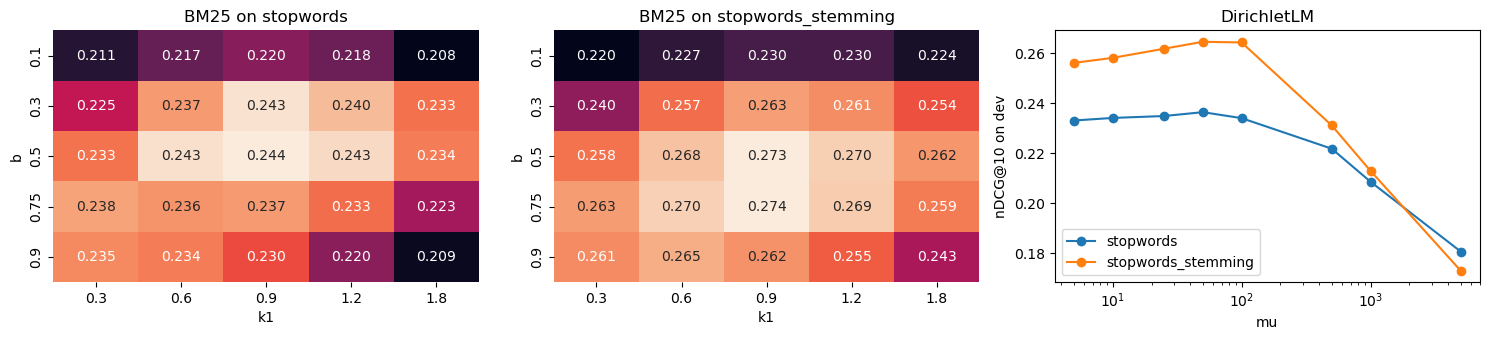

In [13]:
figure, axes = plt.subplots(1, 3, figsize=(15, 3.5))

for axis, index_name in zip(axes[:2], TUNED_INDEX_NAMES):
    grid = bm25_grids[index_name].pivot(index="b", columns="k1", values="nDCG@10")
    sns.heatmap(grid, annot=True, fmt=".3f", cbar=False, ax=axis)
    axis.set_title(f"BM25 on {index_name}")

for index_name, curve in dirichlet_curves.items():
    axes[2].plot(curve["mu"], curve["nDCG@10"], marker="o", label=index_name)
axes[2].set_xscale("log")
axes[2].set_xlabel("mu")
axes[2].set_ylabel("nDCG@10 on dev")
axes[2].set_title("DirichletLM")
axes[2].legend()

plt.tight_layout()
plt.show()

In [14]:
tuned_settings = {}
for index_name in TUNED_INDEX_NAMES:
    bm25_grid = bm25_grids[index_name]
    dirichlet_curve = dirichlet_curves[index_name]

    best_bm25_row = bm25_grid.loc[bm25_grid["nDCG@10"].idxmax()]
    best_dirichlet_row = dirichlet_curve.loc[dirichlet_curve["nDCG@10"].idxmax()]

    tuned_settings[index_name] = {
        "BM25": {"b": float(best_bm25_row["b"]), "k1": float(best_bm25_row["k1"])},
        "DirichletLM": {"mu": float(best_dirichlet_row["mu"])},
    }

tuned_settings

{'stopwords': {'BM25': {'b': 0.5, 'k1': 0.9}, 'DirichletLM': {'mu': 50.0}},
 'stopwords_stemming': {'BM25': {'b': 0.75, 'k1': 0.9},
  'DirichletLM': {'mu': 50.0}}}

## Test results
All four weighting models on both indexes, with the tuned settings. The following notebooks use the stopwords and stemming index.

In [15]:
systems = {}
for index_name in TUNED_INDEX_NAMES:
    index = indexes[index_name]
    systems[f"TF ({index_name})"] = build_retriever(index, "Tf")
    systems[f"TF-IDF ({index_name})"] = build_retriever(index, "TF_IDF")

    for model_name in ["BM25", "DirichletLM"]:
        controls = controls_for_model(model_name, tuned_settings[index_name][model_name])
        systems[f"{model_name} ({index_name})"] = build_retriever(index, model_name, controls)

test_results = pt.Experiment(list(systems.values()), test_queries, test_qrels, RANKING_METRICS,
                             names=list(systems.keys()), round=4)
test_results["query time (ms)"] = [round(milliseconds_per_query(system, test_queries), 1)
                                   for system in systems.values()]
test_results

,name,P@10,R@100,nDCG@5,nDCG@10,nDCG@20,RR@10,query time (ms)
0,TF (stopwords),0.0127,0.2310,0.0315,0.0379,0.0480,0.0478,12.6
1,TF-IDF (stopwords),0.0659,0.5117,0.2061,0.2296,0.2519,0.2846,13.8
2,BM25 (stopwords),0.0665,0.5142,0.2163,0.2396,0.2599,0.2950,13.8
3,DirichletLM (stopwords),0.0670,0.5056,0.2110,0.2389,0.2562,0.2951,15.0
4,TF (stopwords_stemming),0.0097,0.2119,0.0212,0.0275,0.0374,0.0320,13.1
5,TF-IDF (stopwords_stemming),0.0711,0.5557,0.2315,0.2537,0.2773,0.3113,14.7
6,BM25 (stopwords_stemming),0.0702,0.5524,0.2309,0.2541,0.2788,0.3119,14.8
7,DirichletLM (stopwords_stemming),0.0685,0.5412,0.2388,0.2549,0.2774,0.3199,16.1


In [16]:
save_best_parameters(tuned_settings["stopwords_stemming"])
save_results(test_results, "01_ranking_models")